# Phase 2.5 — Targeted symbol and split-readiness review

**Purpose:** Prepare a small, auditable human-review queue before Phase 3 freezes speaker-disjoint splits.

This notebook reads the completed Phase 2 candidate manifest and the existing speaker proposal tables. It does **not** change labels, resolve speaker identities, assign splits, or listen to audio automatically. When you run the final cell, it saves versioned *local* review files under `outputs/`. Those files contain transcripts and speaker metadata and should stay out of the source-only GitHub repository.

Complete Phase 2's conclusion first. Review the generated queues manually, then record decisions with evidence. Unresolved clips/groups can remain outside primary validation and test.

In [1]:
from pathlib import Path
from datetime import datetime
import hashlib
import json

import pandas as pd
from IPython.display import display

# Find the BTP project whether this notebook is in BTP/ or BTP/notebooks/.
current = Path.cwd().resolve()
project = next(
    (folder for folder in (current, *current.parents)
     if (folder / "manifests" / "master_A_v1_1.parquet").is_file()),
    None,
)
if project is None:
    raise FileNotFoundError("Open this notebook from inside the BTP project.")

source_path = project / "outputs/phase2_20261031_205009/phase2_candidates.parquet"
groups_path = project / "review/speaker_groups.csv"
conflicts_path = project / "review/speaker_conflicts.csv"
for path in (source_path, groups_path, conflicts_path):
    if not path.is_file():
        raise FileNotFoundError(path)

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

source_hash = sha256_file(source_path)
candidates = pd.read_parquet(source_path)
groups = pd.read_csv(groups_path, encoding="utf-8-sig")
conflicts = pd.read_csv(conflicts_path, encoding="utf-8-sig")

required = {
    "sample_id", "audio_path", "transcript_raw", "transcript_phase2",
    "duration_decoded", "speaker_group_id", "speaker_status", "train_only",
    "recording_session_id",
}
missing = required - set(candidates.columns)
if missing:
    raise ValueError(f"Phase 2 source lacks columns: {sorted(missing)}")
if candidates["sample_id"].isna().any() or candidates["sample_id"].duplicated().any():
    raise ValueError("Candidate sample IDs must be present and unique.")

print("Phase 2 candidate rows:", len(candidates))
print("Speaker proposals:", len(groups))
print("Recorded speaker conflicts:", len(conflicts))
print("Source SHA-256:", source_hash)

Phase 2 candidate rows: 5086
Speaker proposals: 5
Recorded speaker conflicts: 9
Source SHA-256: cdffb2605f5e0de2168fbc093dc4c7937b808437aa20b0fb5705b596bd7b1681


## 1. Make a small symbol-review queue

The earlier Phase 2 inventory found `:`, `;`, and `[` in 41 distinct candidates. A combining acute accent occurs in one further candidate. The queue preserves the exact label and source locator. It does not guess a correction.

For each row, inspect the symbol in context. Listen only when the transcription convention cannot be resolved from reliable annotation evidence. Record **keep**, **correct**, or **unresolved**, with a reason. Never apply one decision globally without checking its other contexts.

In [2]:
symbols = {
    ":": "colon: check whether intended as IPA length or punctuation",
    ";": "semicolon: meaning varies by context",
    "[": "left bracket: check whether intended as dental notation",
    "\u0301": "combining acute: preserve pending meaning review",
}

def present_symbols(text):
    if not isinstance(text, str):
        raise TypeError("Expected string transcript in Phase 2 candidates.")
    return [symbol for symbol in symbols if symbol in text]

symbol_lists = candidates["transcript_raw"].map(present_symbols)
symbol_mask = symbol_lists.map(bool)
symbol_queue = candidates.loc[
    symbol_mask,
    ["sample_id", "audio_path", "duration_decoded",
     "transcript_raw", "transcript_phase2",
     "speaker_group_id", "speaker_status", "train_only"],
].copy()
symbol_queue["symbols_found"] = symbol_lists.loc[symbol_mask].map(
    lambda values: " ".join(f"U+{ord(symbol):04X}" for symbol in values)
)
symbol_queue["review_decision"] = ""      # keep / correct / unresolved
symbol_queue["reviewed_transcript"] = ""  # fill only for a justified correction
symbol_queue["evidence_or_note"] = ""     # what was heard or annotation rule used
symbol_queue["reviewer"] = ""
symbol_queue["review_date"] = ""
symbol_queue = symbol_queue.sort_values("sample_id").reset_index(drop=True)

print("Unique clips needing targeted symbol review:", len(symbol_queue))
print("Decoded hours represented:",
      round(symbol_queue["duration_decoded"].sum() / 3600, 3))
for symbol, meaning in symbols.items():
    count = int(candidates["transcript_raw"].str.contains(
        symbol, regex=False
    ).sum())
    print(f"U+{ord(symbol):04X}: {count} clips — {meaning}")

# Only IDs and code-point labels are displayed here; full text stays in the
# local review file created at the end of the notebook.
display(symbol_queue[["sample_id", "symbols_found", "duration_decoded"]].head(20))

Unique clips needing targeted symbol review: 42
Decoded hours represented: 0.201
U+003A: 3 clips — colon: check whether intended as IPA length or punctuation
U+003B: 20 clips — semicolon: meaning varies by context
U+005B: 19 clips — left bracket: check whether intended as dental notation
U+0301: 1 clips — combining acute: preserve pending meaning review


,sample_id,symbols_found,duration_decoded
0,A_000264,U+005B,28.88
1,A_000347,U+003B,29.31
2,A_000411,U+005B,25.30
3,A_000445,U+005B,12.86
4,A_000450,U+005B,29.56
5,A_000679,U+003B U+005B,20.27
6,A_001185,U+003B,6.22
7,A_001646,U+003B,17.15
8,A_001787,U+003B,13.88
9,A_001797,U+005B,14.10


## 2. Review proposed merges at the group level

The speaker-group CSV proposes five merges of public IDs. Its confidence labels and name similarities are evidence to inspect, not identity confirmation. A group can be kept together conservatively even when the speakers might differ; the important rule is to avoid putting potentially linked voices across train and held-out splits.

The table below joins each proposal to *current candidate* clip counts and hours. Historical proposal counts can differ because the Phase 1 candidate pool has been filtered.

In [3]:
candidate_groups = (
    candidates.groupby("speaker_group_id", dropna=False)
    .agg(
        candidate_clips=("sample_id", "size"),
        candidate_hours=("duration_decoded", lambda values: values.sum() / 3600),
        train_only=("train_only", "any"),
        statuses=("speaker_status",
                  lambda values: ", ".join(sorted(set(values.dropna().astype(str))))),
    )
    .reset_index()
)
proposal_review = groups.merge(
    candidate_groups,
    on="speaker_group_id",
    how="left",
    suffixes=("_proposal", "_candidate"),
    validate="one_to_one",
)
proposal_review["candidate_clips"] = (
    proposal_review["candidate_clips"].fillna(0).astype(int)
)
proposal_review["candidate_hours"] = proposal_review["candidate_hours"].fillna(0.0)
proposal_review["review_decision"] = ""  # confirm / reject / keep together provisionally
proposal_review["evidence_or_note"] = ""
proposal_review["reviewer"] = ""
proposal_review["review_date"] = ""

display(proposal_review[
    ["speaker_group_id", "public_ids", "confidence", "why_merged",
     "candidate_clips", "candidate_hours", "statuses_candidate", "review_decision"]
])
print("Proposal groups requiring a recorded decision:", len(proposal_review))

,speaker_group_id,public_ids,confidence,why_merged,candidate_clips,candidate_hours,statuses_candidate,review_decision
0,SG_merge_01,6741913a208b312091ae7a04 | 6741f7b68a00b249877...,high,same name stem under >1 public ID,100,0.260344,uncertain_identity,
1,SG_merge_02,6741d7a08a00b24987714f42 | 6867765bff16e00b68f...,possible (not verifiable),manual: look-alike names,226,0.636580,ok,
2,SG_merge_03,673f37a6554540458864b505 | 673f37e516ece267dd1...,high,same name stem under >1 public ID,67,0.179436,uncertain_identity,
3,SG_merge_04,67407b28208b312091ae79c7 | 6741cea4693fd6f659f...,high,same name stem under >1 public ID,53,0.161297,ok,
4,SG_merge_05,673f3d1e9c3f5704d32ba1c8 | 6847f6c712347da7799...,high,same name stem under >1 public ID,218,0.454178,ok,


Proposal groups requiring a recorded decision: 5


## 3. Audit train-only groups and the shared session

The 967 train-only candidates are not 967 separate identity decisions. This cell summarizes them by proposed group. It also checks whether any group mixes train-only and unrestricted clips, and whether a recording session spans multiple proposed groups.

A shared session can be legitimate. Record a conservative grouping decision before splitting so its related clips cannot leak into both train and evaluation.

In [4]:
train_only = candidates["train_only"].fillna(False).astype(bool)
train_group_review = (
    candidates.loc[train_only]
    .groupby("speaker_group_id", dropna=False)
    .agg(
        candidate_clips=("sample_id", "size"),
        candidate_hours=("duration_decoded", lambda values: values.sum() / 3600),
        statuses=("speaker_status",
                  lambda values: ", ".join(sorted(set(values.dropna().astype(str))))),
        sessions=("recording_session_id", "nunique"),
    )
    .reset_index()
    .sort_values("candidate_clips", ascending=False)
)
train_group_review["review_decision"] = ""  # keep train-only / resolved / exclude
train_group_review["evidence_or_note"] = ""
train_group_review["reviewer"] = ""

mixed_groups = (
    candidates.assign(_train_only=train_only)
    .groupby("speaker_group_id", dropna=False)["_train_only"]
    .nunique()
)
cross_session_counts = (
    candidates.groupby("recording_session_id", dropna=False)["speaker_group_id"]
    .nunique(dropna=False)
)
cross_session_ids = cross_session_counts[cross_session_counts.gt(1)].index
session_review = (
    candidates.loc[
        candidates["recording_session_id"].isin(cross_session_ids),
        ["recording_session_id", "sample_id", "speaker_group_id",
         "speaker_status", "train_only", "duration_decoded"],
    ]
    .sort_values(["recording_session_id", "speaker_group_id", "sample_id"])
    .reset_index(drop=True)
)

print("Train-only candidate clips:", int(train_only.sum()))
print("Train-only candidate hours:",
      round(candidates.loc[train_only, "duration_decoded"].sum() / 3600, 3))
print("Proposed train-only groups:", len(train_group_review))
print("Groups mixing train-only and unrestricted status:",
      int(mixed_groups.gt(1).sum()))
print("Sessions spanning proposed groups:", len(cross_session_ids))
display(train_group_review[[
    "speaker_group_id", "candidate_clips", "candidate_hours",
    "statuses", "sessions", "review_decision"
]])
display(session_review[[
    "recording_session_id", "sample_id", "speaker_group_id",
    "speaker_status", "train_only"
]].head(20))

Train-only candidate clips: 967
Train-only candidate hours: 2.474
Proposed train-only groups: 9
Groups mixing train-only and unrestricted status: 0
Sessions spanning proposed groups: 1


,speaker_group_id,candidate_clips,candidate_hours,statuses,sessions,review_decision
5,6867765bff16e00b68f4bba2,378,0.939953,linked_to_pair,243,
6,6867765bff16e00b68f4bba6,222,0.737559,linked_to_pair,168,
7,SG_merge_01,100,0.260344,uncertain_identity,2,
1,673f34fc554540458864b504,81,0.225025,multi_person,1,
8,SG_merge_03,67,0.179436,uncertain_identity,3,
2,673f36ca0984e3815daab2af,64,0.047650,multi_person,1,
0,673f34421f106fded16408cc,32,0.043300,multi_person,1,
3,67407a5b16ece267dd18bfd6,22,0.039764,multi_person,1,
4,6741d6128a00b24987714f41,1,0.000481,linked_to_pair,1,


,recording_session_id,sample_id,speaker_group_id,speaker_status,train_only
0,A20241121132808152109,A_000062,673f34fc554540458864b504,multi_person,True
1,A20241121132808152109,A_000063,673f34fc554540458864b504,multi_person,True
2,A20241121132808152109,A_000064,673f34fc554540458864b504,multi_person,True
3,A20241121132808152109,A_000065,673f34fc554540458864b504,multi_person,True
4,A20241121132808152109,A_001153,673f34fc554540458864b504,multi_person,True
5,A20241121132808152109,A_001154,673f34fc554540458864b504,multi_person,True
6,A20241121132808152109,A_001156,673f34fc554540458864b504,multi_person,True
7,A20241121132808152109,A_001157,673f34fc554540458864b504,multi_person,True
8,A20241121132808152109,A_001158,673f34fc554540458864b504,multi_person,True
9,A20241121132808152109,A_001159,673f34fc554540458864b504,multi_person,True


## 4. Record remaining split-readiness checks

Repeated transcript strings are not duplicate audio. The exact audio-overlap audit and final connected grouping belong in Phase 3, but the decisions in the queues above should be ready first. Do not interpret the original dataset split column as a valid speaker-disjoint split.

In [5]:
repeated_text_rows = int(candidates["transcript_phase2"].duplicated().sum())
print("Repeated normalized transcript rows:", repeated_text_rows)
print("Distinct proposed candidate groups:",
      candidates["speaker_group_id"].nunique(dropna=False))
print("Distinct recording sessions:",
      candidates["recording_session_id"].nunique(dropna=False))
print("Unresolved symbol rows must stay outside primary held-out references.")
print("No exact-audio duplicate decision or split assignment is made here.")

Repeated normalized transcript rows: 398
Distinct proposed candidate groups: 45
Distinct recording sessions: 1745
Unresolved symbol rows must stay outside primary held-out references.
No exact-audio duplicate decision or split assignment is made here.


## Visual summary of review workload

These charts show how many clips contain each flagged symbol and how the train-only workload is distributed across proposed groups. Symbol categories overlap, so their bars must not be added together. The figures do not represent completed review decisions.

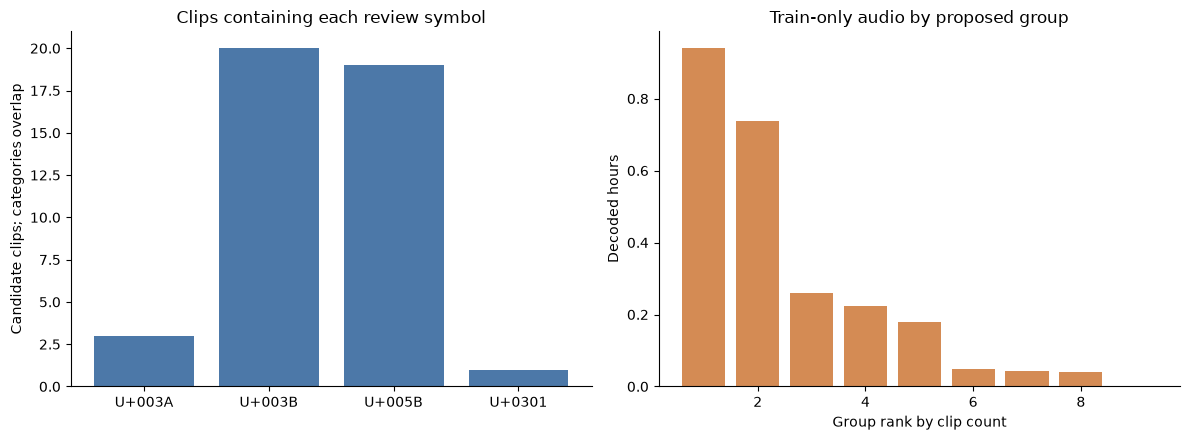

In [6]:
try:
    import matplotlib.pyplot as plt
except ImportError:
    print("Matplotlib is unavailable. Install it in this kernel if you want the plots.")
else:
    labels = [f"U+{ord(symbol):04X}" for symbol in symbols]
    counts = [int(candidates["transcript_raw"].str.contains(
        symbol, regex=False).sum()) for symbol in symbols]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].bar(labels, counts, color="#4c78a8")
    axes[0].set_title("Clips containing each review symbol")
    axes[0].set_ylabel("Candidate clips; categories overlap")
    axes[1].bar(range(1, len(train_group_review) + 1),
                train_group_review["candidate_hours"], color="#d48b54")
    axes[1].set_title("Train-only audio by proposed group")
    axes[1].set_xlabel("Group rank by clip count")
    axes[1].set_ylabel("Decoded hours")
    for ax in axes:
        ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    plt.show()

## 5. Save versioned local review templates

Run this cell once after inspecting the tables. The resulting CSVs contain blank decision fields for your review. Editing those CSVs later does not modify source manifests. Keep the reviewed files and evidence as separate artifacts; do not overwrite the Phase 2 candidate manifest.

In [7]:
run_id = datetime.now().astimezone().strftime("%Y%m%d_%H%M%S")
output_dir = project / "outputs" / f"phase2_5_{run_id}"
output_dir.mkdir(parents=True, exist_ok=False)

symbol_path = output_dir / "symbol_review_queue.csv"
proposal_path = output_dir / "speaker_merge_review.csv"
train_path = output_dir / "train_only_group_review.csv"
session_path = output_dir / "shared_session_examples.csv"
summary_path = output_dir / "summary.json"

symbol_queue.to_csv(symbol_path, index=False, encoding="utf-8-sig")
proposal_review.to_csv(proposal_path, index=False, encoding="utf-8-sig")
train_group_review.to_csv(train_path, index=False, encoding="utf-8-sig")
session_review.to_csv(session_path, index=False, encoding="utf-8-sig")

summary = {
    "phase": "2.5",
    "status": "review_queues_prepared_decisions_pending",
    "created_at": datetime.now().astimezone().isoformat(timespec="seconds"),
    "source": str(source_path.relative_to(project)),
    "source_sha256": source_hash,
    "candidate_rows": int(len(candidates)),
    "symbol_review_rows": int(len(symbol_queue)),
    "symbol_review_hours": float(symbol_queue["duration_decoded"].sum() / 3600),
    "speaker_merge_proposals": int(len(proposal_review)),
    "train_only_candidate_rows": int(train_only.sum()),
    "train_only_groups": int(len(train_group_review)),
    "cross_group_sessions": int(len(cross_session_ids)),
    "exact_audio_overlap_checked": False,
    "split_frozen": False,
}
summary_path.write_text(
    json.dumps(summary, ensure_ascii=False, indent=2) + "\n",
    encoding="utf-8",
)
if sha256_file(source_path) != source_hash:
    raise RuntimeError("Phase 2 source changed during this notebook run.")

print("Review templates saved in:", output_dir)
print("Phase 2 source hash unchanged.")
print("No corrections or speaker decisions were applied automatically.")

Review templates saved in: /Users/kanchanpotdar/Downloads/BTP/outputs/phase2_5_20261031_215057
Phase 2 source hash unchanged.
No corrections or speaker decisions were applied automatically.
